In [1]:
using Revise
using StableRNGs
import LazySets
using LinearAlgebra
using NLsolve
using Plots
using LaTeXStrings

rng = StableRNG(93685)
gr();
# pyplot();
# plotlyjs();

In [2]:
BLAS.set_num_threads(1)

In [3]:
using GaussianSpectralDensities

# Dynamics of a random neural network with one planted memory

$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
$$

$$
\begin{aligned}
\frac{d x_i}{dt} &= -x_i + \sum_{j = 1}^N \tilde{J}_{ij} \tanh x_j \ , \\
\tilde{J} &= \frac{\hat{\bm{x}} \tanh \hat{\bm{x}}}{\|\tanh \hat{\bm{x}}\|^2} + \sigma J \, , \\
\langle J_{ij} J_{kl} \rangle &= \frac{1}{N} \left(\delta_{ik} \delta_{jl} + \tau \delta_{il} \delta_{kj} \right) \, .
\end{aligned}
$$

The memory $\hat{\bm{x}}$ is a randomly sampled vector, and the model
is set up such that, in the absence of coupling noise ($\sigma = 0$),
there is a fixed point at $\bm{x} = \hat{\bm{x}}$. What happens as
noise is turned on, and what is the effect of symmetry $\tau$?

Note that the $\tanh$ breaks rotational symmetry, so different
$\hat{\bm{x}}$ with the same norm do not necessarily give equivalent
dynamics. Should this inform our choice of measure for sampling
memories? No, I think sampling something like a Gaussian $\hat{\bm{x}}$
is the most sensible approach. It maintains permutation invariance
but not full rotational invariance, which actually seems desirable in
a nonlinear model.

Let's run some simulations.

In [4]:
function network_f!(dx, x, J̃, t)
    mul!(dx, J̃, tanh.(x))
    dx .-= x
end

function network_jac!(jac, x, J̃, t)
    for j in 1:length(x)
        for i in 1:length(x)
            jac[i, j] = J̃[i, j] / (cosh(x[j])^2)
        end
        jac[j, j] -= one(eltype(jac))
    end
end

function poor_mans_network_jac!(jac, x, J̃, t, dx)
    xx = copy(x)
    fx = similar(xx)
    fxdx = similar(xx)
    network_f!(fx, xx, J̃, t)
    for j in 1:N
        xx[j] += dx
        network_f!(fxdx, xx, J̃, t) 
        jac[:, j] = (fxdx - fx) / (xx[j] - x[j])
        xx[j] = x[j]
    end
end

poor_mans_network_jac! (generic function with 1 method)

In [5]:
ftype = Float64

N = 256
s = one(ftype)
x̂ = s * randn(rng, ftype, N)
tx̂ = tanh.(x̂)
Ĵ = x̂ * tx̂' / dot(tx̂, tx̂)
Ĵ[diagind(Ĵ)] .= zero(ftype);

In [6]:
σ = ftype(0.4)
τ = ftype(0.5)

J = randn(rng, ftype, N, N) / sqrt(ftype(N))
J = partially_hermitize(J, τ)
J[diagind(J)] .= zero(ftype)

J̃ = Ĵ + σ * J;

In [7]:
# Verify Jacobian
jaca = similar(J̃)
jacb = similar(J̃)
network_jac!(jaca, x̂, J̃, zero(ftype))
poor_mans_network_jac!(jacb, x̂, J̃, zero(ftype), sqrt(eps(ftype)))
opnorm(jacb - jaca)

5.851961581834808e-7

In [8]:
sol = nlsolve(
    (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
    (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
    x̂;
    method=:newton,
    ftol=sqrt(eps(ftype)),
)
if !converged(sol)
    error("failed to converge")
end
x₀ = sol.zero
jac = similar(J̃)
network_jac!(jac, x₀, J̃, zero(ftype))
jacevs = eigvals(jac)
println(maximum(real(jacevs)))

-0.515898065751941


In [9]:
R = Diagonal(cosh.(x₀).^(-2))
ensemble = MatrixEnsemble(Ĵ * R - I, σ * I, R, τ)

Mevs = unique(eigvals(ensemble.M))
A, _J = sample(rng, ftype, ensemble)
Aevs = eigvals(A; sortby=nothing);

In [10]:
region = spectral_region(Aevs)
xs, ys, zs = autogrid(region);

In [11]:
i, j = 20, 105
za = zs[i, j + 1]
zb = zs[i - 1, j]
zc = zs[i, j];

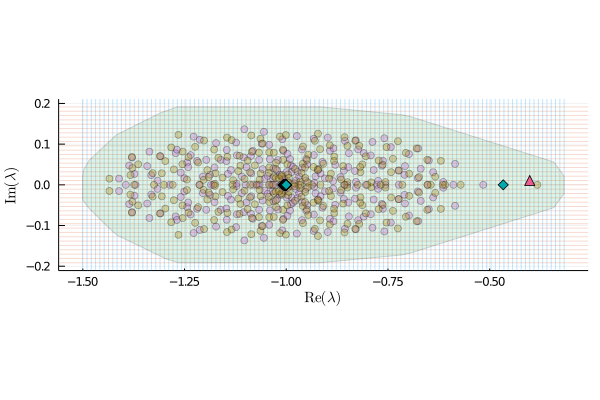

In [12]:
p = vline(xs, label="", alpha=0.25, xlims=(xs[1], xs[end]))
hline!(p, ys, label="", alpha=0.25, ylims=(ys[1], ys[end]))
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

scatter!(p, xs[[j]], ys[[i]], markershape=:utriangle, markersize=5, label="")

In [13]:
objective = Fixk();
algorithm = Rampδ²();

In [14]:
verbosity = 3;

solver = SpectralSolver(ensemble, objective, algorithm);
solutiona = solve!(solver, za; verbosity=verbosity, store_trace=true);
solutionb = solve!(solver, zb; verbosity=verbosity, store_trace=true);
qa, δa² = solutiona.q, solutiona.δ²;
qb, δb² = solutionb.q, solutionb.δ²;
qc0, δc0² = GaussianSpectralDensities.select(qa, qb, δa², δb²);
GaussianSpectralDensities.print_q(qc0);
GaussianSpectralDensities.print_δ²(δc0²);
solutionc = solve!(
    solver, zc,
    qc0, δc0²;
    verbosity=verbosity, store_trace=true,
);

 z = -0.391 + i 0.011
---------------------------------------------------------------------------------------------
    μ       γ²         δ²                  q                k                   r
-------  ----------  ---------  ------------------------  ---------  ------------------------
  1.000   2.559e+02  2.560e+02   8.270e-03 + i-1.451e-04  3.589e-03   3.431e+01 + i-6.009e-01
  1.000   1.279e+02  1.280e+02   1.464e-02 + i-2.577e-04  6.862e-03   5.142e+01 + i-9.023e-01
  1.000   6.390e+01  6.400e+01   2.523e-02 + i-4.471e-04  1.286e-02   7.491e+01 + i-1.320e+00
  1.000   3.191e+01  3.200e+01   4.219e-02 + i-7.562e-04  2.345e-02   1.063e+02 + i-1.887e+00
  1.000   1.592e+01  1.600e+01   6.791e-02 + i-1.240e-03  4.111e-02   1.468e+02 + i-2.645e+00
  1.000   7.931e+00  8.000e+00   1.040e-01 + i-1.954e-03  6.825e-02   1.969e+02 + i-3.629e+00
  1.000   3.947e+00  4.000e+00   1.493e-01 + i-2.920e-03  1.056e-01   2.540e+02 + i-4.844e+00
  1.000   1.961e+00  2.000e+00   1.990e-01 + i-4.0

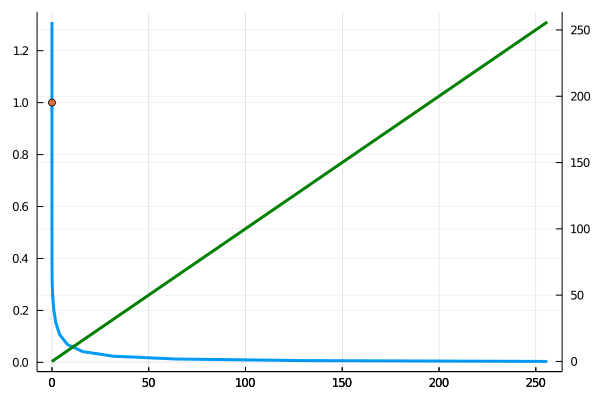

In [15]:
sol = solutionb

plot(sol.trace.γ², sol.trace.k, lw=3, label="")
scatter!([sol.γ²], [sol.k], label="")
plot!(twinx(), sol.trace.γ², sol.trace.δ², lw=3, color=:green, label="")

In [16]:
chunks_per_thread = 1
problem = SpectralProblem(ensemble, objective, zs);
solution = solve(problem, algorithm; chunks_per_thread=chunks_per_thread);

In [17]:
ρ, ρxs, ρys = spectral_density(solution, xs, ys);

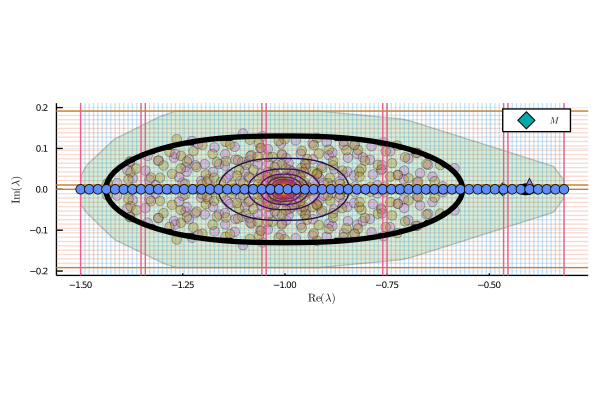

In [18]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(
    p,
    region,
    alpha=0.2,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label=L"M")

chunk_rows, chunk_cols = GaussianSpectralDensities.chunk_indices(
    size(zs), chunks_per_thread * Threads.nthreads()
)
chunk_xs, chunk_ys = xs[vcat(chunk_cols...)], ys[vcat(chunk_rows...)]
vline!(p, chunk_xs, label="")
hline!(p, chunk_ys, label="")

contour!(p, ρxs, ρys, ρ, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, linewidth=4)

vline!(p, [0.0], color=:black, label="")

ii, jj = 20, 105
scatter!(p, xs[[jj]], ys[[ii]], markershape=:utriangle, markersize=5, label="")

function plot_section(x, y, level)
    p = plot(x, y, linewidth=4, label="")
    return hline!(p, [level], color=:black, label="")
end

function plot_sections(xs, ys, f; x0=0.0, y0=0.0, level=0.0)
    i, j = argmin(abs2.(ρys .- y0)), argmin(abs2.(ρxs .- x0))
    return [plot_section(x, y, level) for (x, y) in ((xs, f[i, :]), (ys, f[:, j]))]
end

l = @layout [a{0.75w} [b; c]]
plot(p, plot_sections(ρxs, ρys, ρ, x0=-1)..., layout=l, size=(800, 300))

xxs = autogrid(region, 32^2)[1]
scatter!(p, xxs, zero(xxs); label="")

In [19]:
using Roots
using Random

# Function evaluations
#     sqrt(n):         16   32   48   64
# --------------------------------------
# Bisection:           52   51   50   49
# FalsePosition{1}:    24   15   32   14
# FalsePosition{2}:    20   16   20   16
# FalsePosition{3}:    15   25   29   20
# FalsePosition{4}:    18   24   16   21
# FalsePosition{5}:    28   23   15   12
# FalsePosition{6}:    22   16   22   23
# FalsePosition{7}:    21   23   13   26
# FalsePosition{8}:    35   15   18   24
# FalsePosition{9}:    22   13   20   15
# FalsePosition{10}:   28   21   22   20
# FalsePosition{11}:   25   37   33   20
# FalsePosition{12}:   14   15   15   14  # Clear winner
function xmax(ensemble, algorithm, J, A, n=32^2, method=FalsePosition(12))
    solver = SpectralSolver(ensemble, Fixk(), algorithm)
    mul!(A, J, ensemble.R)
    lmul!(ensemble.L, A)
    A .+= ensemble.M
    xs = autogrid!(A, n)[1]
    local i
    for ii in length(xs):-1:1
        sol = solve!(solver, complex(xs[ii]))
        if sol.γ² !== missing && sol.γ² >= 0
            i = ii
            break
        end
    end

    zproblem = Roots.ZeroProblem(
        method,
        x -> solve!(solver, complex(x), sol.q, sol.δ²).γ²,
        xs[i:i + 1];
    )
    result = find_zero!(zproblem)
    return result, zproblem
end

xmax (generic function with 3 methods)

In [20]:
# ns = (16:16:64).^2
# methods = [Bisection(), (FalsePosition(i) for i in 1:12)...]
# fnevals = [
#     xmax(ensemble, algorithm, _J, A, n, method)[2].state.fnevals
#     for method in methods, n in ns
# ];

In [21]:
# using Printf

# label_width = 20
# println("# Function evaluations")
# print(rpad("#     sqrt(n):", label_width))
# for n in ns
#     @printf("   %2i", sqrt(n))
# end
# println()
# println("# " * ("-" ^ (label_width - 2 + 5 * length(ns))))
# for i in 1:size(fnevals, 1)
#     print(rpad("# $(typeof(methods[i])):", label_width))
#     for j in 1:size(fnevals, 2)
#         @printf("   %2i", fnevals[i, j])
#     end
#     println()
# end

In [22]:
function fpoint(J̃, x₀)
    ftype = eltype(x₀)
    sol = nlsolve(
        (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
        (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
        x₀;
        method=:newton,
        ftol=sqrt(eps(ftype)),
    )
    if !converged(sol)
        error("failed to converge")
    end
    return sol.zero
end

fpoint (generic function with 1 method)

In [23]:
x₀ = x̂
σs = ftype(0.05):ftype(0.05):ftype(1.5)
xmaxs = fill(ftype(NaN), length(σs))
x₀s = fill(ftype(NaN), (length(x₀), length(σs)))
for (i, σ) in enumerate(σs)
    J̃ = Ĵ + σ * J
    try
        x₀s[:, i] = x₀ = fpoint(J̃, x₀)
    catch
        break
    end
    R = Diagonal(cosh.(x₀).^(-2))
    ensemble = MatrixEnsemble(Ĵ * R - I, σ * I, R, τ)
    xmaxs[i] = xmax(ensemble, algorithm, _J, A)[1]
end

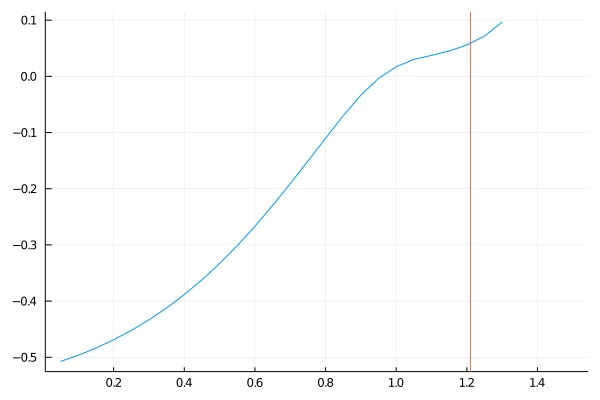

In [24]:
vl = [1.21]
plot(σs, xmaxs, label="")
vline!(vl, label="")

We're onto something here. What do we actually want to accomplish?

This shows the real part of the rightmost eigenvalue for different levels of noise. The fixed point goes unstable when this curve crosses zero. What I'd like to do is to find this point for different values of $\tau$, the symmetry parameter, so that I can draw a phase diagram. Ideally I'll sample a few different noise instantiations for each pair of values.

I dont care about locating the phase boundary very exactly---it's blurred by noise at accessible matrix sizes anyway. Hence, no further root finding is relevant, I should just sample the real value of the rightmost eigenvalue and use contour plotting to distinguish the phases.

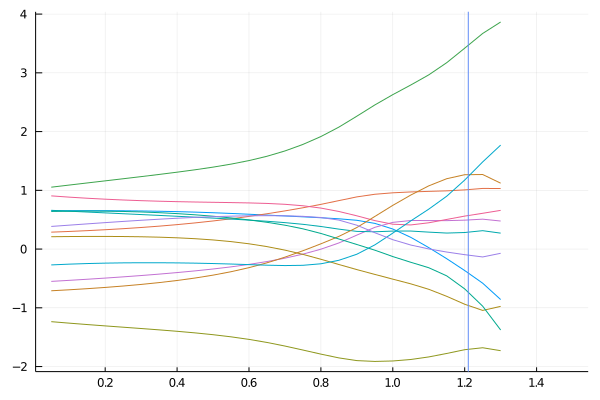

In [25]:
plot(σs, x₀s[1:12, :]', label="")
vline!(vl, label="")

In [26]:
display([σs xmaxs])

30×2 Array{Float64,2}:
 0.05   -0.507404
 0.1    -0.496402
 0.15   -0.483609
 0.2    -0.468925
 0.25   -0.45222
 0.3    -0.433341
 0.35   -0.412129
 0.4    -0.388431
 0.45   -0.362118
 0.5    -0.333097
 0.55   -0.301325
 0.6    -0.266855
 0.65   -0.229915
 ⋮     
 0.95   -0.00373619
 1.0     0.0171022
 1.05    0.0301122
 1.1     0.0373872
 1.15    0.0451689
 1.2     0.0558957
 1.25    0.0714853
 1.3     0.0967221
 1.35  NaN
 1.4   NaN
 1.45  NaN
 1.5   NaN

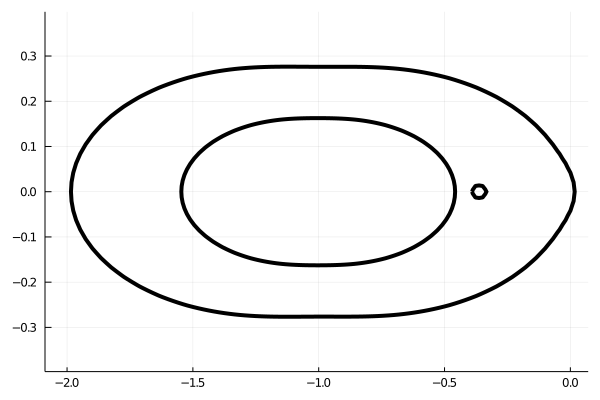

In [27]:
M = similar(ensemble.M)
R = similar(ensemble.R)
x₀ = x̂
σs = ftype(0.5):ftype(0.5):ftype(1.5)
x₀s = fill(ftype(NaN), (length(x₀), length(σs)))
p = plot()
for (i, σ) in enumerate(σs)
    J̃ = Ĵ + σ * J
    try
        x₀s[:, i] = x₀ = fpoint(J̃, x₀)
    catch
        break
    end
    R .= Diagonal(cosh.(x₀).^(-2))
    mul!(M, Ĵ, R)
    M[diagind(M)] .-= 1
    ensemble = MatrixEnsemble(M, σ * I, R, τ)
    mul!(A, _J, ensemble.R)
    lmul!(ensemble.L, A)
    A .+= ensemble.M
    xs, ys, zs = autogrid(spectral_region!(A))
    problem = SpectralProblem(ensemble, Fixk(), zs)
    solution = solve(problem, algorithm)
    contour!(
        p, xs, ys, solution.γ²; levels=[0.0], color=:black, linewidth=4, colorbar=false
    )
end
p

In [28]:
[σs x₀s[1, :]]

3×2 Array{Float64,2}:
 0.5    0.618604
 1.0    0.34127
 1.5  NaN